# Simulasi Reinforcement Learning: Pengelolaan Keuangan & Kehidupan Harian Mahasiswa (30 Hari, 5 Step/Hari)

Notebook ini menjalankan pelatihan, evaluasi berkala, penyimpanan checkpoint terbaik, dan pencatatan eksperimen yang **reproducible** untuk `StudentLifeEnv` (150 step/bulan, 1 saldo operasional tunggal Rp 1.465.000, fitur bekal, masak pagi berat, dan tidur otomatis) menggunakan `MaskablePPO` (`StudentPPOAgent`).

In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gymnasium as gym
import stable_baselines3
import sb3_contrib

from src.env import StudentLifeEnv
from src.agents import StudentPPOAgent, set_global_seed

print(f"Python/Torch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")
print(
    f"Gymnasium: {gym.__version__} | SB3: {stable_baselines3.__version__} | "
    f"SB3-Contrib: {sb3_contrib.__version__}"
)

Python/Torch: 2.15.0+cpu | CUDA: False
Gymnasium: 1.4.0 | SB3: 2.9.2 | SB3-Contrib: 2.9.2


## 1. Konfigurasi Eksperimen & Validasi Environment

In [10]:
ENV_CONFIG_PATH = "env_config.yaml"
EXPERIMENT_NAME = "maskable_ppo_5step_unified_budget"
RUNS_ROOT_DIR = "runs"

TRAIN_CONFIG = {
    "seed": 42,
    "num_environments": 4,
    "features_dim": 128,
    "hidden_dim": 128,
    "policy_hidden_layers": [128, 128],
    "value_hidden_layers": [128, 128],
    "learning_rate": 1e-4,               # Halus untuk fine-tuning pasca-BC
    "rollout_steps_per_env": 300,       # 300 * 4 env = 1.200 step (8 episode penuh) per update
    "batch_size": 120,
    "num_epochs": 10,
    "discount_factor_gamma": 0.995,      # Matches budget_potential_shaping.gamma in env_config.yaml
    "gae_lambda": 0.98,
    "clip_range": 0.2,
    "entropy_coefficient": 0.015,
    "target_kl": 0.02,                  # Rem KL otomatis mencegah BC policy collapse
    "use_action_masking": True,         # MaskablePPO (sb3-contrib)
    "share_features_extractor": False,  # Pisahkan extractor Actor & Critic
    "device": "auto",
}

TRAINING_SCHEDULE = {
    "total_timesteps": 3_000_000,
    "eval_interval_steps": 100_000,
    "eval_episodes": 10,
    "final_eval_episodes": 20,
    "eval_seed": 1000,
    "survival_phase_timesteps": 1_000_000,   # Target: 100% completion before 500k; afterward optimize leftover balance
}

with open(ENV_CONFIG_PATH, "r", encoding="utf-8") as config_file:
    active_env_config = yaml.safe_load(config_file)

sample_env = StudentLifeEnv(yaml_path=ENV_CONFIG_PATH)
print("Observation space:", sample_env.observation_space)
print("Action space:", sample_env.action_space, "| total mask logits:", sample_env.action_masks().shape[0])
print(
    "Budget bulanan:",
    f"Rp {active_env_config['finance']['monthly_budget']:,.0f}",
    "| Kuota:",
    f"Rp {active_env_config['finance']['fixed_expenses']['mobile_data']:,.0f}",
    "| Saldo operasional tunggal:",
    f"Rp {sample_env.finance.initial_operational_budget_idr:,.0f}",
)

Observation space: Box(-1.0, inf, (50,), float32)
Action space: MultiDiscrete([ 8  2  6 18  2 15]) | total mask logits: 51
Budget bulanan: Rp 1,500,000 | Kuota: Rp 35,000 | Saldo operasional tunggal: Rp 1,465,000


## 2. Training Loop Reproducible & Best-Model Checkpointing

In [ ]:
set_global_seed(TRAIN_CONFIG["seed"])

agent = StudentPPOAgent(
    yaml_path=ENV_CONFIG_PATH,
    **TRAIN_CONFIG,
    verbose=0,
)

bc_summary = agent.pretrain_bc(num_episodes=80, epochs=25, learning_rate=1e-3, entropy_coef=0.03)

run_result = agent.train_with_logging(
    **TRAINING_SCHEDULE,
    experiment_name=EXPERIMENT_NAME,
    runs_root_dir=RUNS_ROOT_DIR,
    progress_bar=False,
)

run_dir = Path(run_result["run_dir"])
eval_history_df = run_result["eval_history_df"]
final_summary = run_result["final_summary"]
final_episodes_df = run_result["final_episodes_df"]
best_episode_trace_df = run_result["best_episode_trace_df"]

print(f"\nRun selesai. Direktori artefak: {run_dir}")
print(f"Best checkpoint pada timestep: {run_result['best_checkpoint_timestep']:,}")
print(
    f"Episode evaluasi terbaik: episode {final_summary['best_eval_episode_index']} "
    f"(seed {final_summary['best_eval_episode_seed']}, reward {final_summary['max_episode_reward']:.2f})"
)

[BC Pretrain] Epoch  1/25 | actor_loss=4.7571 | critic_loss=10.6043 | entropy=5.352
[BC Pretrain] Epoch  5/25 | actor_loss=1.2878 | critic_loss=6.7015 | entropy=1.576
[BC Pretrain] Epoch 10/25 | actor_loss=0.8259 | critic_loss=4.4280 | entropy=1.044
[BC Pretrain] Epoch 15/25 | actor_loss=0.5684 | critic_loss=3.2962 | entropy=0.763
[BC Pretrain] Epoch 20/25 | actor_loss=0.4194 | critic_loss=2.7981 | entropy=0.569
[BC Pretrain] Epoch 25/25 | actor_loss=0.2850 | critic_loss=2.3738 | entropy=0.424
Step  250000/3000000 | Fase:  survive | Reward: -481.13 +/- 31.52 | Complete:   0.0% | Hari: 22.5/30 | Kelas:  98.6% | Sisa: Rp    18,617 | Masak/Bekal:  0.0 | CCWS/Kafe: 32.8 [BEST]
Step  500000/3000000 | Fase:  survive | Reward: -450.71 +/- 13.95 | Complete:   0.0% | Hari: 23.8/30 | Kelas: 100.0% | Sisa: Rp    62,053 | Masak/Bekal:  0.0 | CCWS/Kafe: 30.1 [BEST]
Step  750000/3000000 | Fase:  survive | Reward: -437.27 +/- 16.23 | Complete:   0.0% | Hari: 24.4/30 | Kelas: 100.0% | Sisa: Rp    23,6

KeyboardInterrupt: 

## 2b. Eval best / lanjut training tanpa variabel dari cell training

In [4]:
from pathlib import Path
import json
import pandas as pd

RUN_DIR = Path(RUN_DIR) if 'RUN_DIR' in globals() else max((p for p in Path(RUNS_ROOT_DIR).glob('*') if (p/'train_config.json').exists()), key=lambda p: p.stat().st_mtime)
run_dir = RUN_DIR
assert (run_dir/'best_model.zip').exists()
eval_history_df = pd.read_csv(run_dir/'eval_history.csv') if (run_dir/'eval_history.csv').exists() else pd.DataFrame()
recovery_agent = StudentPPOAgent.load_from_run(run_dir, checkpoint='best')
final_summary, final_episodes_df, best_episode_trace_df = recovery_agent.evaluate_detailed(num_episodes=20, deterministic=True, eval_seed=11000, record_best_episode_trace=True)
final_summary['eval_seed'] = 11000
(run_dir/'manual_eval_summary.json').write_text(json.dumps(final_summary, indent=2), encoding='utf-8')
final_episodes_df.to_csv(run_dir/'manual_eval_episodes.csv', index=False)
best_episode_trace_df.to_csv(run_dir/'manual_best_episode_trace.csv', index=False)
print(f"completion={final_summary['completion_rate']:.0%} | hari={final_summary['mean_days_survived']:.1f}/30 | sisa=Rp {final_summary['mean_final_balance_idr']:,.0f}")

# Resume: ganti blok evaluasi di atas dengan baris di bawah jika ingin lanjut training.
# agent = StudentPPOAgent(yaml_path=str(RUN_DIR/'env_config_snapshot.yaml'), **TRAIN_CONFIG, verbose=0)
# run_result = agent.train_with_logging(**TRAINING_SCHEDULE, experiment_name=EXPERIMENT_NAME, runs_root_dir=RUNS_ROOT_DIR, progress_bar=False, resume_from_run=RUN_DIR, resume_checkpoint='best')
# run_dir, eval_history_df, final_summary, final_episodes_df, best_episode_trace_df = (run_result[k] for k in ('run_dir','eval_history_df','final_summary','final_episodes_df','best_episode_trace_df'))

completion=0% | hari=28.9/30 | sisa=Rp 2,731


## 3. Ringkasan Metrik Evaluasi & Alokasi Anggaran 1 Bulan (Best Checkpoint)

In [5]:
summary_table = pd.DataFrame(
    list(final_summary.items()),
    columns=["metric", "value"],
)
display(summary_table)

# Tabel alokasi pengeluaran 1 bulan (pedoman distribusi budget hasil RL)
initial_budget = float(sample_env.finance.initial_operational_budget_idr)
allocation_rows = [
    ("transport", final_summary["mean_spent_transport_idr"]),
    ("grocery_cooking", final_summary["mean_spent_grocery_idr"]),
    ("external_food_warung_snack", final_summary["mean_spent_external_food_idr"]),
    ("cafe", final_summary["mean_spent_cafe_idr"]),
    ("minimarket_impulse", final_summary["mean_spent_minimarket_impulse_idr"]),
    ("remaining_balance", final_summary["mean_final_balance_idr"]),
]
allocation_df = pd.DataFrame(allocation_rows, columns=["category", "mean_idr"])
allocation_df["share_of_operational_budget_pct"] = (
    allocation_df["mean_idr"] / initial_budget * 100.0
)
display(allocation_df.round({"mean_idr": 0, "share_of_operational_budget_pct": 2}))

display(
    final_episodes_df[
        [
            "episode_index",
            "episode_reward",
            "episode_steps",
            "termination_reason",
            "class_attendance_rate",
            "final_balance_idr",
            "spent_transport_idr",
            "spent_grocery_idr",
            "spent_external_food_idr",
            "spent_cafe_idr",
            "mean_energy",
            "mean_hunger",
            "mean_mood",
            "mean_academic_stress",
            "total_spoiled_units",
            "grocery_shop_count",
            "cook_fresh_count",
            "meal_prep_count",
            "reheat_prep_count",
            "pack_bekal_count",
            "eat_bekal_count",
            "apartemen_warung_count",
            "delivery_food_count",
            "warung_hemat_count",
            "warung_variasi_count",
            "ccws_stay_count",
            "cafe_session_count",
            "night_cramming_count",
        ]
    ]
)

,metric,value
0,mean_episode_reward,-357.870726
1,std_episode_reward,63.442204
2,min_episode_reward,-500.162717
3,max_episode_reward,-287.620535
4,best_eval_episode_index,10.000000
5,best_eval_episode_seed,11010.000000
6,mean_episode_steps,144.300000
7,mean_days_survived,28.860000
8,completion_rate,0.000000
9,mean_class_attendance_rate,0.978279


,category,mean_idr,share_of_operational_budget_pct
0,transport,414037.0,28.26
1,grocery_cooking,7175.0,0.49
2,external_food_warung_snack,824850.0,56.30
3,cafe,130555.0,8.91
4,minimarket_impulse,85652.0,5.85
5,remaining_balance,2731.0,0.19


,episode_index,episode_reward,episode_steps,termination_reason,class_attendance_rate,final_balance_idr,spent_transport_idr,spent_grocery_idr,spent_external_food_idr,spent_cafe_idr,...,reheat_prep_count,pack_bekal_count,eat_bekal_count,apartemen_warung_count,delivery_food_count,warung_hemat_count,warung_variasi_count,ccws_stay_count,cafe_session_count,night_cramming_count
0,0,-377.685627,144,fatal_starvation,0.972973,215.0,420579.0,0.0,793000.0,166272.0,...,0,0,0,22,0,19,12,28,5,0
1,1,-318.182799,143,fatal_starvation,1.000000,3589.0,431750.0,0.0,832000.0,134826.0,...,0,0,0,22,3,19,10,34,4,2
2,2,-305.041332,144,fatal_energy_collapse,1.000000,9075.0,397319.0,0.0,827000.0,135791.0,...,0,0,0,23,2,18,11,28,4,0
3,3,-363.256338,147,fatal_energy_collapse,0.973684,0.0,397867.0,72000.0,800000.0,126797.0,...,0,0,0,23,1,22,8,30,4,0
4,4,-468.388770,149,fatal_starvation,0.925000,0.0,426181.0,0.0,866000.0,133136.0,...,0,0,0,22,2,18,14,29,4,0
5,5,-500.162717,150,fatal_starvation,0.925000,0.0,393434.0,35500.0,824000.0,140126.0,...,0,1,1,24,2,18,10,28,4,0
6,6,-460.381958,149,fatal_energy_collapse,0.925000,0.0,401891.0,0.0,863000.0,130891.0,...,0,0,0,25,1,19,12,27,4,1
7,7,-314.108164,144,fatal_energy_collapse,1.000000,582.0,396373.0,12000.0,812000.0,132895.0,...,0,0,0,24,1,19,10,28,4,0
8,8,-472.269542,149,fatal_energy_collapse,0.925000,0.0,438259.0,0.0,856000.0,121199.0,...,0,0,0,24,1,21,11,31,4,3
9,9,-366.574919,144,fatal_starvation,0.972973,0.0,414948.0,0.0,831000.0,114969.0,...,0,0,0,24,3,18,9,30,4,1


## 4. Visualisasi Progres Evaluasi & Trace Episode Terbaik (30 Hari)

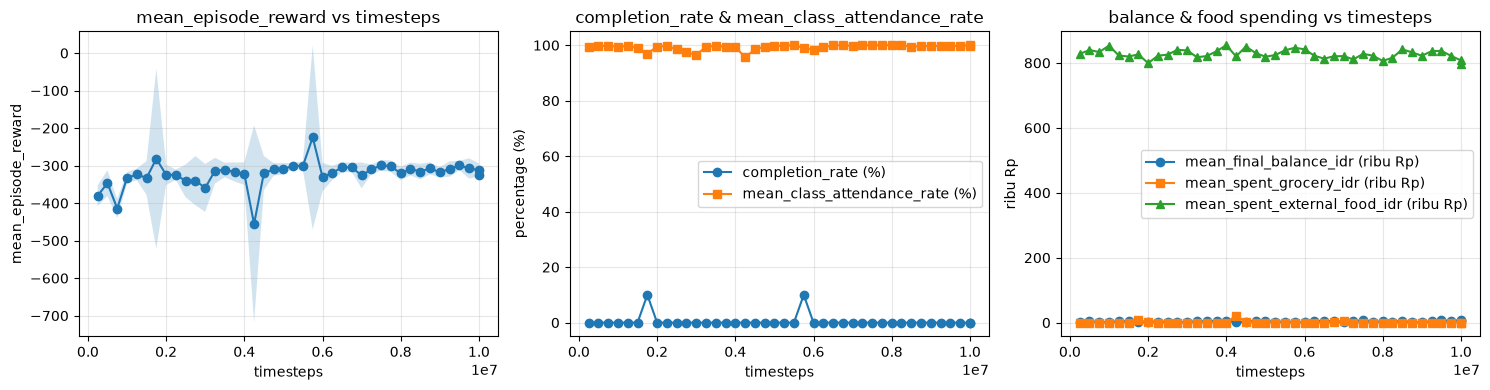

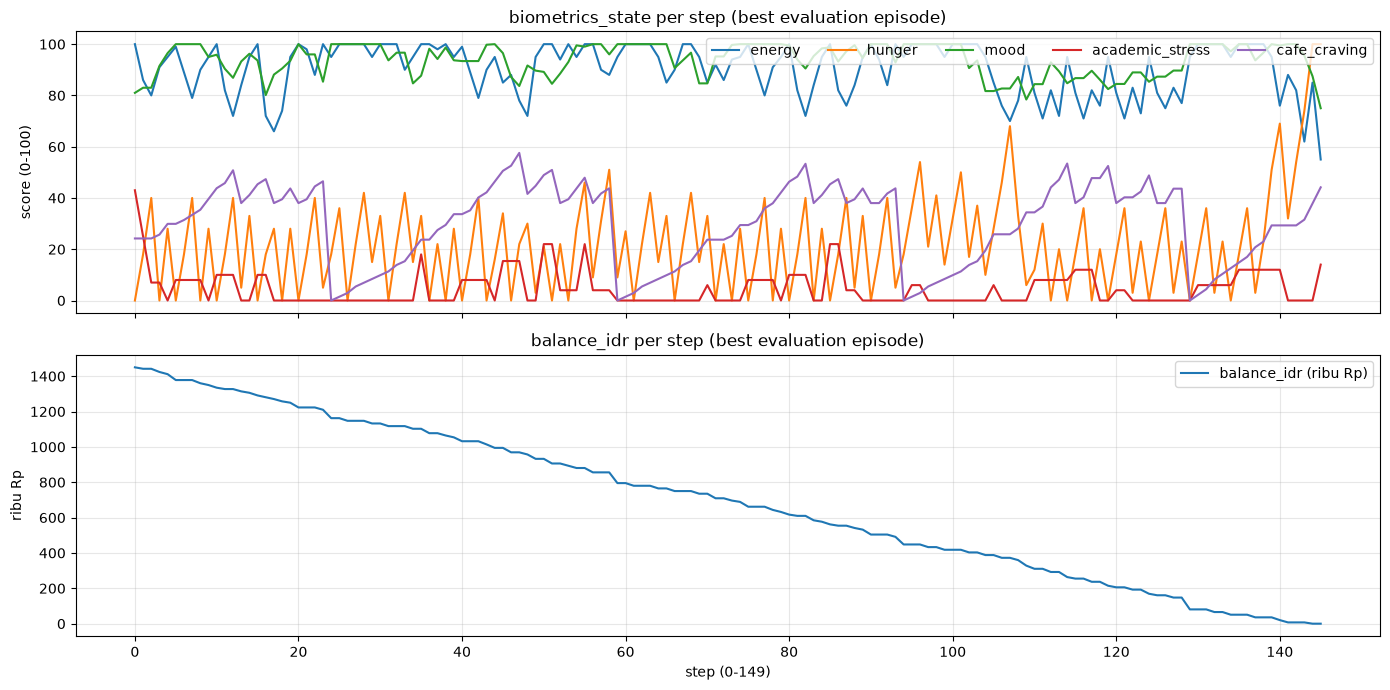

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(eval_history_df["timesteps"], eval_history_df["mean_episode_reward"], marker="o")
axes[0].fill_between(
    eval_history_df["timesteps"],
    eval_history_df["mean_episode_reward"] - eval_history_df["std_episode_reward"],
    eval_history_df["mean_episode_reward"] + eval_history_df["std_episode_reward"],
    alpha=0.2,
)
axes[0].set_title("mean_episode_reward vs timesteps")
axes[0].set_xlabel("timesteps")
axes[0].set_ylabel("mean_episode_reward")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    eval_history_df["timesteps"],
    eval_history_df["completion_rate"] * 100.0,
    marker="o",
    label="completion_rate (%)",
)
axes[1].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_class_attendance_rate"] * 100.0,
    marker="s",
    label="mean_class_attendance_rate (%)",
)
axes[1].set_title("completion_rate & mean_class_attendance_rate")
axes[1].set_xlabel("timesteps")
axes[1].set_ylabel("percentage (%)")
axes[1].set_ylim(-5, 105)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_final_balance_idr"] / 1_000.0,
    marker="o",
    label="mean_final_balance_idr (ribu Rp)",
)
axes[2].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_spent_grocery_idr"] / 1_000.0,
    marker="s",
    label="mean_spent_grocery_idr (ribu Rp)",
)
axes[2].plot(
    eval_history_df["timesteps"],
    eval_history_df["mean_spent_external_food_idr"] / 1_000.0,
    marker="^",
    label="mean_spent_external_food_idr (ribu Rp)",
)
axes[2].set_title("balance & food spending vs timesteps")
axes[2].set_xlabel("timesteps")
axes[2].set_ylabel("ribu Rp")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if not best_episode_trace_df.empty:
    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

    for column_name in ["energy", "hunger", "mood", "academic_stress", "cafe_craving"]:
        axes[0].plot(best_episode_trace_df["step"], best_episode_trace_df[column_name], label=column_name)
    axes[0].set_title("biometrics_state per step (best evaluation episode)")
    axes[0].set_ylabel("score (0-100)")
    axes[0].set_ylim(-5, 105)
    axes[0].legend(ncol=5, loc="upper right")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        best_episode_trace_df["step"],
        best_episode_trace_df["balance_idr"] / 1_000.0,
        label="balance_idr (ribu Rp)",
    )
    axes[1].set_title("balance_idr per step (best evaluation episode)")
    axes[1].set_xlabel("step (0-149)")
    axes[1].set_ylabel("ribu Rp")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## 5. Trace Detail Episode Terbaik (Hari 1 s/d Hari 30: 5 Step per Hari)

In [7]:
if "run_dir" not in globals():
    run_folders = sorted(
        [path for path in Path(RUNS_ROOT_DIR).iterdir() if path.is_dir()],
        key=lambda path: path.name,
    )
    assert run_folders, "Belum ada folder run di dalam direktori runs/."
    run_dir = run_folders[-1]

best_trace_csv_path = run_dir / "best_episode_trace.csv"
if best_trace_csv_path.exists():
    best_episode_trace_df = pd.read_csv(best_trace_csv_path)
else:
    episodes_table = pd.read_csv(run_dir / "final_eval_episodes.csv")
    best_episode_row = episodes_table.loc[episodes_table["episode_reward"].idxmax()]
    loaded_best_agent = StudentPPOAgent.load_from_run(run_dir, checkpoint="best")
    best_episode_trace_df = loaded_best_agent.record_episode_trace(
        episode_seed=int(best_episode_row["episode_seed"]),
        deterministic=True,
    )
    best_episode_trace_df.to_csv(best_trace_csv_path, index=False)

print(
    f"Run: {run_dir.name} | "
    f"Seed episode terbaik: {int(best_episode_trace_df['episode_seed'].iloc[0])} | "
    f"Total step: {len(best_episode_trace_df)} | "
    f"Total reward: {best_episode_trace_df['cumulative_reward'].iloc[-1]:.2f}"
)

detailed_columns = [
    "day",
    "day_name",
    "time_slot",
    "hours",
    "class_scheduled",
    "location_before",
    "location_after",
    "executed_route",
    "executed_activity",
    "executed_meal_mode",
    "meal_signature",
    "purchased_groceries",
    "step_spend_idr",
    "balance_idr",
    "energy",
    "hunger",
    "mood",
    "academic_stress",
    "cafe_craving",
    "rice_stock",
    "egg_stock",
    "chicken_stock",
    "tempe_stock",
    "meal_prep_stock",
    "packed_lunch_stock",
    "events_summary",
    "step_reward",
    "cumulative_reward",
]

with pd.option_context(
    "display.max_rows", 160,
    "display.max_columns", 40,
    "display.width", 280,
    "display.max_colwidth", 65,
):
    display(best_episode_trace_df[detailed_columns].round({
        "step_spend_idr": 0,
        "balance_idr": 0,
        "energy": 1,
        "hunger": 1,
        "mood": 1,
        "academic_stress": 1,
        "cafe_craving": 1,
        "step_reward": 2,
        "cumulative_reward": 2,
    }))

daily_summary_df = (
    best_episode_trace_df.groupby(["day", "day_name"], sort=True)
    .agg(
        total_spend_idr=("step_spend_idr", "sum"),
        end_balance_idr=("balance_idr", "last"),
        routes_used=("executed_route", lambda s: ", ".join(r for r in s if r != "stay") or "stay"),
        activities=("executed_activity", lambda s: " -> ".join(s)),
        meals=("executed_meal_mode", lambda s: ", ".join(m for m in s if m != "skip") or "skip"),
        mean_energy=("energy", "mean"),
        mean_mood=("mood", "mean"),
        mean_stress=("academic_stress", "mean"),
        daily_reward=("step_reward", "sum"),
    )
    .reset_index()
)

with pd.option_context("display.max_rows", 35, "display.max_columns", 20, "display.width", 260, "display.max_colwidth", 90):
    display(daily_summary_df.round({
        "total_spend_idr": 0,
        "end_balance_idr": 0,
        "mean_energy": 1,
        "mean_mood": 1,
        "mean_stress": 1,
        "daily_reward": 2,
    }))

Run: 20261127_000823_maskable_ppo_5step_unified_budget_2ea7100f | Seed episode terbaik: 11010 | Total step: 146 | Total reward: -287.62


,day,day_name,time_slot,hours,class_scheduled,location_before,location_after,executed_route,executed_activity,executed_meal_mode,meal_signature,purchased_groceries,step_spend_idr,balance_idr,energy,hunger,mood,academic_stress,cafe_craving,rice_stock,egg_stock,chicken_stock,tempe_stock,meal_prep_stock,packed_lunch_stock,events_summary,step_reward,cumulative_reward
0,1,monday,pagi_awal,06:00-09:30,False,apartment,apartment,stay,rest_or_sleep,apartemen_warung,apartemen_warung,NaN,15000.0,1450000.0,100.0,0.0,81.0,43.0,24.2,0,0,0,0,0,0,new_daily_task,-0.11,-0.11
1,1,monday,sesi_1,09:30-12:15,False,apartment,campus,transit_ccws_ojol,ccws_stay,skip,NaN,NaN,8197.0,1441803.0,86.0,18.0,83.0,25.0,24.2,0,0,0,0,0,0,NaN,0.94,0.84
2,1,monday,sesi_2,12:15-15:15,False,campus,campus,stay,ccws_stay,skip,NaN,NaN,0.0,1441803.0,80.0,40.0,83.0,7.0,24.2,0,0,0,0,0,0,rain,2.18,3.02
3,1,monday,sesi_3,15:15-18:30,True,campus,campus,stay,attend_class,warung_variasi,warung_variasi,NaN,18000.0,1423803.0,91.0,0.0,91.5,7.0,25.7,0,0,0,0,0,0,rain,6.67,9.69
4,1,monday,malam,18:30-22:30,False,campus,apartment,direct_ojol,room_study,skip,NaN,NaN,12477.0,1411326.0,95.0,28.0,96.5,0.0,29.9,0,0,0,0,0,0,NaN,1.34,11.03
5,2,tuesday,pagi_awal,06:00-09:30,False,apartment,campus,transit_ccws_ojol,ccws_stay,warung_hemat,warung_hemat,NaN,33304.0,1378022.0,99.0,0.0,100.0,8.0,29.9,0,0,0,0,0,0,new_daily_task | ccws_minimarket_impulse,-1.29,9.74
6,2,tuesday,sesi_1,09:30-12:15,True,campus,campus,stay,attend_class,skip,NaN,NaN,0.0,1378022.0,89.0,18.0,100.0,8.0,31.4,0,0,0,0,0,0,NaN,9.20,18.94
7,2,tuesday,sesi_2,12:15-15:15,True,campus,campus,stay,attend_class,skip,NaN,NaN,0.0,1378022.0,79.0,40.0,100.0,8.0,33.4,0,0,0,0,0,0,rain,8.61,27.55
8,2,tuesday,sesi_3,15:15-18:30,True,campus,campus,stay,attend_class,warung_variasi,warung_variasi,NaN,18000.0,1360022.0,90.0,0.0,100.0,8.0,35.4,0,0,0,0,0,0,boredom(-2.1),6.89,34.44
9,2,tuesday,malam,18:30-22:30,False,campus,apartment,transit_ccws_ojol,room_study,skip,NaN,NaN,10213.0,1349809.0,95.0,28.0,95.0,0.0,39.6,0,0,0,0,0,0,rain,1.69,36.13


,day,day_name,total_spend_idr,end_balance_idr,routes_used,activities,meals,mean_energy,mean_mood,mean_stress,daily_reward
0,1,monday,53674.0,1411326.0,"transit_ccws_ojol, direct_ojol",rest_or_sleep -> ccws_stay -> ccws_stay -> attend_class -> room_study,"apartemen_warung, warung_variasi",90.4,87.0,16.4,11.03
1,2,tuesday,61517.0,1349809.0,"transit_ccws_ojol, transit_ccws_ojol",ccws_stay -> attend_class -> attend_class -> attend_class -> room_study,"warung_hemat, warung_variasi",90.4,99.0,6.4,25.10
2,3,wednesday,43820.0,1305989.0,"transit_ccws_ojol, transit_ccws_ojol",room_study -> attend_class -> attend_class -> ccws_stay -> room_study,"apartemen_warung, warung_hemat",86.6,92.5,6.0,20.47
3,4,thursday,56053.0,1249936.0,"transit_ccws_ojol, transit_ccws_ojol",room_study -> attend_class -> ccws_stay -> attend_class -> room_study,"apartemen_warung, warung_hemat",81.4,89.2,4.0,18.89
4,5,friday,87444.0,1162492.0,transit_ccws_ojol,ccws_stay -> wait_at_department -> attend_class -> wait_at_department -> cafe_session,"warung_variasi, warung_hemat",96.2,95.5,0.0,10.81
5,6,saturday,30000.0,1132492.0,stay,rest_or_sleep -> rest_or_sleep -> rest_or_sleep -> rest_or_sleep -> room_study,"apartemen_warung, apartemen_warung",99.0,100.0,0.0,13.81
6,7,sunday,30000.0,1102492.0,stay,rest_or_sleep -> rest_or_sleep -> rest_or_sleep -> room_study -> room_study,"apartemen_warung, apartemen_warung",97.0,94.3,0.0,13.13
7,8,monday,48511.0,1053981.0,"transit_ccws_ojol, transit_ccws_ojol",rest_or_sleep -> ccws_stay -> wait_at_department -> attend_class -> room_study,"warung_variasi, warung_hemat",98.6,94.5,3.6,16.69
8,9,tuesday,59589.0,994392.0,"transit_ccws_ojol, transit_ccws_ojol",ccws_stay -> attend_class -> attend_class -> attend_class -> room_study,"warung_hemat, warung_variasi",90.4,96.0,6.4,26.51
9,10,wednesday,62027.0,932365.0,"transit_ccws_ojol, transit_ccws_ojol",room_study -> attend_class -> attend_class -> ccws_stay -> room_study,"warung_variasi, apartemen_warung",83.6,89.7,9.2,17.49


## 6. Perbandingan Antar-Eksperimen & Reproduksi dari Snapshot Run

In [8]:
master_summary_path = Path(RUNS_ROOT_DIR) / "experiments_summary.csv"
if master_summary_path.exists():
    experiments_df = pd.read_csv(master_summary_path)
    preferred_cols = [
        "run_id",
        "experiment_name",
        "env_config_sha256",
        "use_action_masking",
        "seed",
        "total_timesteps",
        "best_checkpoint_timestep",
        "mean_episode_reward",
        "completion_rate",
        "mean_class_attendance_rate",
        "mean_final_balance_idr",
        "mean_spent_transport_idr",
        "mean_spent_grocery_idr",
        "mean_spent_external_food_idr",
        "mean_spent_cafe_idr",
        "mean_cook_fresh_count",
        "mean_eat_bekal_count",
        "mean_spoiled_units",
    ]
    available_cols = [col for col in preferred_cols if col in experiments_df.columns]
    display(experiments_df[available_cols].sort_values(by="mean_episode_reward", ascending=False))

reloaded_agent = StudentPPOAgent.load_from_run(run_dir, checkpoint="best")
recheck_summary, _, _ = reloaded_agent.evaluate_detailed(
    num_episodes=TRAINING_SCHEDULE["final_eval_episodes"],
    deterministic=True,
    eval_seed=TRAINING_SCHEDULE["eval_seed"] + 10_000,
)
print(
    "Verifikasi reload dari snapshot:",
    f"original={final_summary['mean_episode_reward']:.4f}",
    f"| reloaded={recheck_summary['mean_episode_reward']:.4f}",
)

,run_id,experiment_name,env_config_sha256,use_action_masking,seed,total_timesteps,best_checkpoint_timestep,mean_episode_reward,completion_rate,mean_class_attendance_rate,mean_final_balance_idr,mean_spent_transport_idr,mean_spent_grocery_idr,mean_spent_external_food_idr,mean_spent_cafe_idr,mean_cook_fresh_count,mean_eat_bekal_count,mean_spoiled_units
0,20261125_221435_ppo_residual_baseline_8983b576,ppo_residual_baseline,8983b576c5c5,NaN,42,200640,120960,906.743232,1.00,1.000000,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.0
6,20261126_213628_maskable_ppo_5step_unified_bud...,maskable_ppo_5step_unified_budget,42c17b5679f5,True,42,3000000,3000000,843.756440,1.00,1.000000,126639.40,382874.60,1775.0,816800.0,0.0,0.15,0.00,0.0
1,20261125_224522_ppo_residual_baseline_fe81d6e5,ppo_residual_baseline,fe81d6e54004,NaN,42,200640,161280,749.288246,0.75,1.000000,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.0
5,20261126_112109_maskable_ppo_5step_unified_bud...,maskable_ppo_5step_unified_budget,3c9e725652b0,True,42,250800,176400,549.300817,0.00,0.981464,2755.50,425184.55,0.0,856100.0,18972.3,0.00,0.00,0.0
2,20261125_231931_ppo_residual_baseline_4c381550,ppo_residual_baseline,4c381550abe4,NaN,42,200640,161280,485.191304,0.00,0.998684,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.0
3,20261125_233008_ppo_residual_baseline_deb8b2a4,ppo_residual_baseline,deb8b2a4c0f0,NaN,42,200640,141120,474.236099,0.00,1.000000,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.0
4,20261125_235830_maskable_ppo_5step_unified_bud...,maskable_ppo_5step_unified_budget,38a0e737ecc9,True,42,250800,100800,240.127953,0.00,0.945854,1251.50,273995.35,0.0,970600.0,126731.0,0.00,0.00,0.0
7,20261127_000823_maskable_ppo_5step_unified_bud...,maskable_ppo_5step_unified_budget,2ea7100f2404,True,42,10000800,1750000,-357.870726,0.00,0.978279,2730.75,414037.30,7175.0,824850.0,130555.3,0.35,0.05,0.0


Verifikasi reload dari snapshot: original=-357.8707 | reloaded=-357.8707
